In [5]:
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

df = pd.read_csv(Path("../data/raw/creditcard.csv"))

X = df.drop(columns="Class")
y = df["Class"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50,
    stratify=y_temp, random_state=42
)

def add_features(features):
    result = features.copy()
    result["log_amount"] = np.log1p(result["Amount"])
    return result

X_train = add_features(X_train)
X_val = add_features(X_val)
X_test = add_features(X_test)

print("Training rows:", len(X_train))
print("Validation rows:", len(X_val))
print("Test rows reserved for final evaluation:", len(X_test))

Training rows: 199364
Validation rows: 42721
Test rows reserved for final evaluation: 42722


In [6]:
from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
)

def evaluate(name, y_true, scores, threshold=0.50):
    predictions = (scores >= threshold).astype(int)

    return {
        "model": name,
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "f1": f1_score(y_true, predictions, zero_division=0),
        "average_precision": average_precision_score(y_true, scores),
        "roc_auc": roc_auc_score(y_true, scores),
    }

In [7]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)

baseline_scores = baseline.predict_proba(X_val)[:, 1]
results = [evaluate("Class-prior baseline", y_val, baseline_scores)]

display(pd.DataFrame(results).round(4))

,model,precision,recall,f1,average_precision,roc_auc
0,Class-prior baseline,0.0,0.0,0.0,0.0017,0.5


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    )
)

logistic_model.fit(X_train, y_train)

logistic_scores = logistic_model.predict_proba(X_val)[:, 1]
results.append(evaluate("Logistic Regression", y_val, logistic_scores))

display(pd.DataFrame(results).round(4))

,model,precision,recall,f1,average_precision,roc_auc
0,Class-prior baseline,0.0000,0.0000,0.0000,0.0017,0.5000
1,Logistic Regression,0.0654,0.8784,0.1217,0.6261,0.9686


In [9]:
from sklearn.metrics import confusion_matrix

for threshold in [0.50, 0.80, 0.95]:
    predictions = (logistic_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_val, predictions).ravel()

    print(f"\nThreshold: {threshold:.2f}")
    print(f"Fraud correctly caught (TP): {tp}")
    print(f"Legitimate transactions falsely flagged (FP): {fp}")
    print(f"Fraud missed (FN): {fn}")
    print(f"Legitimate correctly cleared (TN): {tn}")


Threshold: 0.50
Fraud correctly caught (TP): 65
Legitimate transactions falsely flagged (FP): 929
Fraud missed (FN): 9
Legitimate correctly cleared (TN): 41718

Threshold: 0.80
Fraud correctly caught (TP): 63
Legitimate transactions falsely flagged (FP): 297
Fraud missed (FN): 11
Legitimate correctly cleared (TN): 42350

Threshold: 0.95
Fraud correctly caught (TP): 61
Legitimate transactions falsely flagged (FP): 98
Fraud missed (FN): 13
Legitimate correctly cleared (TN): 42549


In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier

tree_model = HistGradientBoostingClassifier(
    max_iter=150,
    max_leaf_nodes=15,
    learning_rate=0.08,
    l2_regularization=1.0,
    random_state=42
)

tree_model.fit(X_train, y_train)

tree_scores = tree_model.predict_proba(X_val)[:, 1]
results.append(evaluate("Gradient Boosting", y_val, tree_scores))

display(
    pd.DataFrame(results)
      .sort_values("average_precision", ascending=False)
      .round(4)
)

,model,precision,recall,f1,average_precision,roc_auc
2,Gradient Boosting,0.9167,0.7432,0.8209,0.8094,0.9849
1,Logistic Regression,0.0654,0.8784,0.1217,0.6261,0.9686
0,Class-prior baseline,0.0000,0.0000,0.0000,0.0017,0.5000


## Threshold Tuning

The default classification threshold is 0.5.

For fraud detection, we tune the threshold to understand the trade-off
between precision and recall and select a threshold appropriate for
fraud-risk detection.

In [11]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

threshold_results = []

for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:

    y_pred_threshold = (tree_scores >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_val, y_pred_threshold, zero_division=0),
        "recall": recall_score(y_val, y_pred_threshold, zero_division=0),
        "f1": f1_score(y_val, y_pred_threshold, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

display(
    threshold_df.round(4)
)

,threshold,precision,recall,f1
0,0.1,0.8116,0.7568,0.7832
1,0.2,0.8750,0.7568,0.8116
2,0.3,0.8871,0.7432,0.8088
3,0.4,0.9016,0.7432,0.8148
4,0.5,0.9167,0.7432,0.8209
5,0.6,0.9483,0.7432,0.8333
6,0.7,0.9643,0.7297,0.8308
7,0.8,0.9615,0.6757,0.7937
8,0.9,0.9796,0.6486,0.7805


In [12]:
best_threshold = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

print("Best threshold based on F1:")
print(best_threshold)

Best threshold based on F1:
threshold    0.600000
precision    0.948276
recall       0.743243
f1           0.833333
Name: 5, dtype: float64


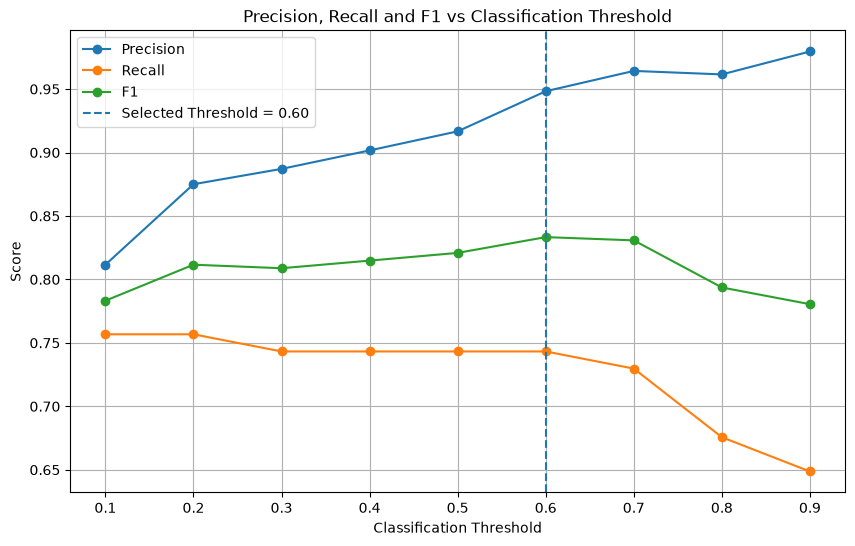

In [13]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    threshold_df["threshold"],
    threshold_df["precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["threshold"],
    threshold_df["f1"],
    marker="o",
    label="F1"
)

plt.axvline(
    x=0.6,
    linestyle="--",
    label="Selected Threshold = 0.60"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Precision, Recall and F1 vs Classification Threshold")
plt.legend()
plt.grid(True)

plt.show()

### Threshold Selection

The Gradient Boosting model achieved its highest validation F1-score
at a classification threshold of 0.60.

At this threshold:

- Precision = 94.83%
- Recall = 74.32%
- F1-score = 83.33%

The threshold will be retained for subsequent fraud-risk prediction
experiments.

## XGBoost Model

XGBoost is evaluated as an additional tree-based model for fraud
classification. Performance will be compared using precision,
recall, F1-score, PR-AUC, and ROC-AUC.

In [2]:
import sys

print(sys.executable)

d:\Graduation-Projects--main\fraud-risk-system\.venv\Scripts\python.exe


In [2]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.


In [3]:
import xgboost as xgb

print("XGBoost version:", xgb.__version__)

XGBoost version: 3.4.1


In [14]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

xgb_scores = xgb_model.predict_proba(X_val)[:, 1]

results.append(
    evaluate(
        "XGBoost",
        y_val,
        xgb_scores
    )
)

display(
    pd.DataFrame(results)
    .sort_values("average_precision", ascending=False)
    .round(4)
)

,model,precision,recall,f1,average_precision,roc_auc
3,XGBoost,0.9661,0.7703,0.8571,0.8232,0.9783
2,Gradient Boosting,0.9167,0.7432,0.8209,0.8094,0.9849
1,Logistic Regression,0.0654,0.8784,0.1217,0.6261,0.9686
0,Class-prior baseline,0.0000,0.0000,0.0000,0.0017,0.5000


## Baseline Model Comparison

The baseline models are compared using precision, recall, F1-score,
PR-AUC, and ROC-AUC. Because fraud detection is highly imbalanced,
PR-AUC and recall are particularly important evaluation metrics.

In [15]:
comparison_df = (
    pd.DataFrame(results)
    .sort_values("average_precision", ascending=False)
    .reset_index(drop=True)
)

display(comparison_df.round(4))

,model,precision,recall,f1,average_precision,roc_auc
0,XGBoost,0.9661,0.7703,0.8571,0.8232,0.9783
1,Gradient Boosting,0.9167,0.7432,0.8209,0.8094,0.9849
2,Logistic Regression,0.0654,0.8784,0.1217,0.6261,0.9686
3,Class-prior baseline,0.0000,0.0000,0.0000,0.0017,0.5000


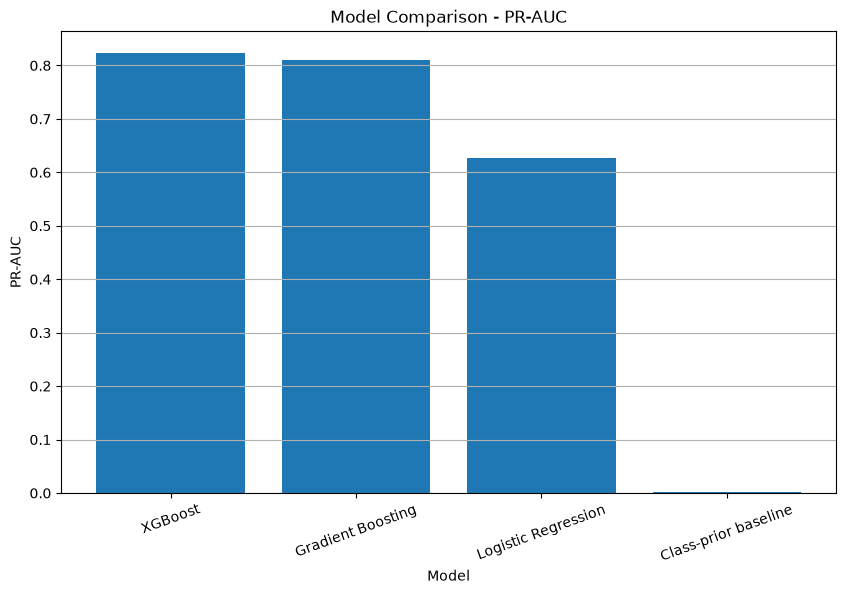

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    comparison_df["model"],
    comparison_df["average_precision"]
)

plt.xlabel("Model")
plt.ylabel("PR-AUC")
plt.title("Model Comparison - PR-AUC")

plt.xticks(rotation=20)
plt.grid(axis="y")

plt.show()

## Class Imbalance Handling

The fraud class is significantly smaller than the legitimate class.
Class weighting will be evaluated to increase the importance of
fraudulent transactions during model training.

In [28]:
fraud_count = (y_train == 1).sum()
legitimate_count = (y_train == 0).sum()

scale_pos_weight = legitimate_count / fraud_count

print("Legitimate transactions:", legitimate_count)
print("Fraudulent transactions:", fraud_count)
print("Scale positive weight:", scale_pos_weight)

Legitimate transactions: 199020
Fraudulent transactions: 344
Scale positive weight: 578.546511627907


In [29]:
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score
import pandas as pd

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": tree_model,
    "XGBoost": xgb_model
}

results = []

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "PR-AUC": average_precision_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(results)

comparison_df

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.065590,0.878378,0.122066,0.967005,0.791715
1,Random Forest,0.965517,0.756757,0.848485,0.963538,0.822590
2,XGBoost,0.933333,0.756757,0.835821,0.961355,0.835060


In [30]:
comparison_df.sort_values("F1 Score", ascending=False)

,Model,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
1,Random Forest,0.965517,0.756757,0.848485,0.963538,0.822590
2,XGBoost,0.933333,0.756757,0.835821,0.961355,0.835060
0,Logistic Regression,0.065590,0.878378,0.122066,0.967005,0.791715


In [31]:
thresholds = np.arange(0.1, 0.91, 0.01)

rf_prob = tree_model.predict_proba(X_test)[:, 1]

threshold_results = []

for threshold in thresholds:
    rf_pred = (rf_prob >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_test, rf_pred, zero_division=0),
        "recall": recall_score(y_test, rf_pred, zero_division=0),
        "f1": f1_score(y_test, rf_pred, zero_division=0)
    })

threshold_df = pd.DataFrame(threshold_results)

best_rf_threshold = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

best_rf_threshold

threshold    0.450000
precision    0.965517
recall       0.756757
f1           0.848485
Name: 35, dtype: float64

In [32]:
best_rf_threshold

threshold    0.450000
precision    0.965517
recall       0.756757
f1           0.848485
Name: 35, dtype: float64

In [33]:
best_rf_threshold = threshold_df.loc[
    threshold_df["f1"].idxmax()
]

best_rf_threshold

threshold    0.450000
precision    0.965517
recall       0.756757
f1           0.848485
Name: 35, dtype: float64

In [34]:
rf_prob = tree_model.predict_proba(X_test)[:, 1]

rf_best_pred = (
    rf_prob >= best_rf_threshold["threshold"]
).astype(int)

In [35]:
rf_precision = precision_score(y_test, rf_best_pred)
rf_recall = recall_score(y_test, rf_best_pred)
rf_f1 = f1_score(y_test, rf_best_pred)

print("Optimized Random Forest")
print("Threshold :", best_rf_threshold["threshold"])
print("Precision :", rf_precision)
print("Recall    :", rf_recall)
print("F1 Score  :", rf_f1)
print("ROC-AUC   :", roc_auc_score(y_test, rf_prob))
print("PR-AUC    :", average_precision_score(y_test, rf_prob))

Optimized Random Forest
Threshold : 0.44999999999999984
Precision : 0.9655172413793104
Recall    : 0.7567567567567568
F1 Score  : 0.8484848484848485
ROC-AUC   : 0.9635377851120677
PR-AUC    : 0.8225895034748688


In [36]:
cm = confusion_matrix(y_test, rf_best_pred)

print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives :", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives :", tp)

[[42646     2]
 [   18    56]]

True Negatives : 42646
False Positives: 2
False Negatives: 18
True Positives : 56


## Outcome
fraud-detection flow is now:

Data → Feature Engineering → Random Forest → Probability → Optimized Threshold → Fraud/Legitimate

converting our output into probablity

In [37]:
risk_score = (rf_prob * 100).round(2)

risk_level = pd.cut(
    risk_score,
    bins=[-1, 29, 59, 79, 100],
    labels=["Low", "Medium", "High", "Critical"]
)

risk_results = pd.DataFrame({
    "Actual": y_test.values,
    "Fraud_Probability": rf_prob,
    "Risk_Score": risk_score,
    "Risk_Level": risk_level,
    "Prediction": rf_best_pred
})

risk_results.head(10)

,Actual,Fraud_Probability,Risk_Score,Risk_Level,Prediction
0,0,0.000002,0.0,Low,0
1,0,0.000014,0.0,Low,0
2,0,0.000004,0.0,Low,0
3,0,0.000011,0.0,Low,0
4,0,0.000006,0.0,Low,0
5,0,0.000004,0.0,Low,0
6,0,0.000007,0.0,Low,0
7,0,0.000003,0.0,Low,0
8,0,0.000013,0.0,Low,0
9,0,0.000033,0.0,Low,0


In [38]:
risk_results["Risk_Level"].value_counts().sort_index()

Risk_Level
Low         42661
Medium          3
High            1
Critical       57
Name: count, dtype: int64

In [39]:
def fraud_decision(row):
    if row["Risk_Score"] >= 80:
        return "Block Transaction"
    elif row["Risk_Score"] >= 60:
        return "Manual Review"
    elif row["Risk_Score"] >= 30:
        return "Monitor"
    else:
        return "Approve"


risk_results["Decision"] = risk_results.apply(
    fraud_decision,
    axis=1
)

risk_results.head(10)

,Actual,Fraud_Probability,Risk_Score,Risk_Level,Prediction,Decision
0,0,0.000002,0.0,Low,0,Approve
1,0,0.000014,0.0,Low,0,Approve
2,0,0.000004,0.0,Low,0,Approve
3,0,0.000011,0.0,Low,0,Approve
4,0,0.000006,0.0,Low,0,Approve
5,0,0.000004,0.0,Low,0,Approve
6,0,0.000007,0.0,Low,0,Approve
7,0,0.000003,0.0,Low,0,Approve
8,0,0.000013,0.0,Low,0,Approve
9,0,0.000033,0.0,Low,0,Approve


In [40]:
risk_results["Decision"].value_counts()

Decision
Approve              42661
Block Transaction       57
Monitor                  3
Manual Review            1
Name: count, dtype: int64

In [41]:
!pip install shap

   ---------------------------------------- 0.0/41.9 MB ? eta -:--:--
   ---------------------------------------- 0.3/41.9 MB ? eta -:--:--
    --------------------------------------- 0.5/41.9 MB 1.2 MB/s eta 0:00:34
    --------------------------------------- 0.8/41.9 MB 1.5 MB/s eta 0:00:28
   - -------------------------------------- 1.3/41.9 MB 1.8 MB/s eta 0:00:23
   -- ------------------------------------- 2.1/41.9 MB 2.2 MB/s eta 0:00:18
   -- ------------------------------------- 2.6/41.9 MB 2.2 MB/s eta 0:00:18
   --- ------------------------------------ 3.4/41.9 MB 2.5 MB/s eta 0:00:16
   ---- ----------------------------------- 4.5/41.9 MB 2.9 MB/s eta 0:00:14
   ----- ---------------------------------- 5.2/41.9 MB 3.0 MB/s eta 0:00:13
   ------ --------------------------------- 6.6/41.9 MB 3.4 MB/s eta 0:00:11
   ------- -------------------------------- 7.3/41.9 MB 3.4 MB/s eta 0:00:11
   -------- ------------------------------- 8.4/41.9 MB 3.6 MB/s eta 0:00:10
   --------- 

In [42]:
import shap
import matplotlib.pyplot as plt

In [43]:
explainer = shap.TreeExplainer(tree_model)

In [44]:
X_shap = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=42
)

shap_values = explainer.shap_values(X_shap)

In [45]:
type(shap_values)

numpy.ndarray

In [46]:
np.array(shap_values).shape

(1000, 31)

In [47]:
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean_Abs_SHAP": np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    "Mean_Abs_SHAP",
    ascending=False
)

shap_importance.head(15)

,Feature,Mean_Abs_SHAP
4,V4,0.681968
14,V14,0.399614
0,Time,0.173718
11,V11,0.161700
29,Amount,0.157719
26,V26,0.153404
12,V12,0.145555
24,V24,0.145168
16,V16,0.144052
21,V21,0.138832


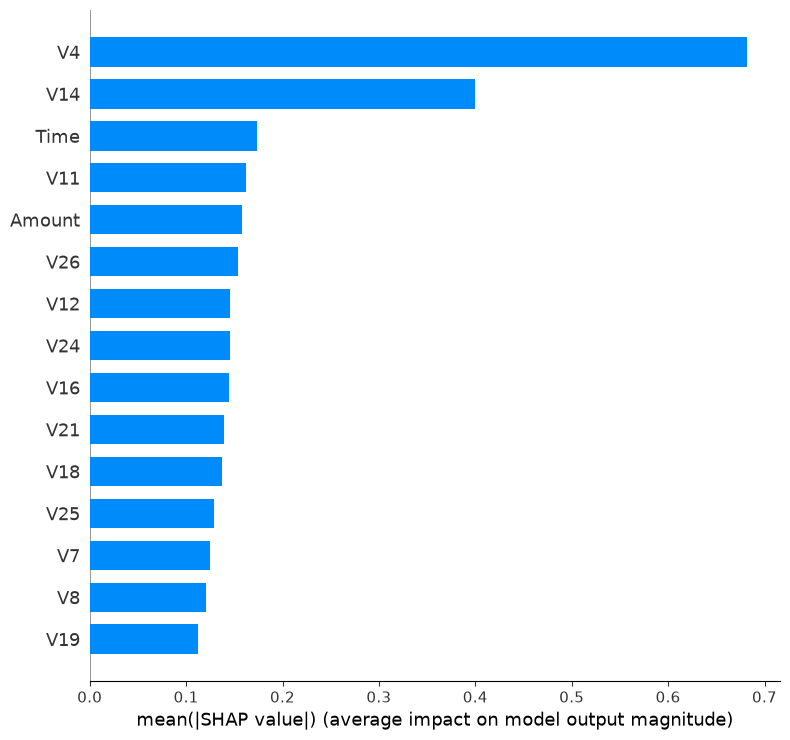

In [48]:
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.tight_layout()
plt.show()

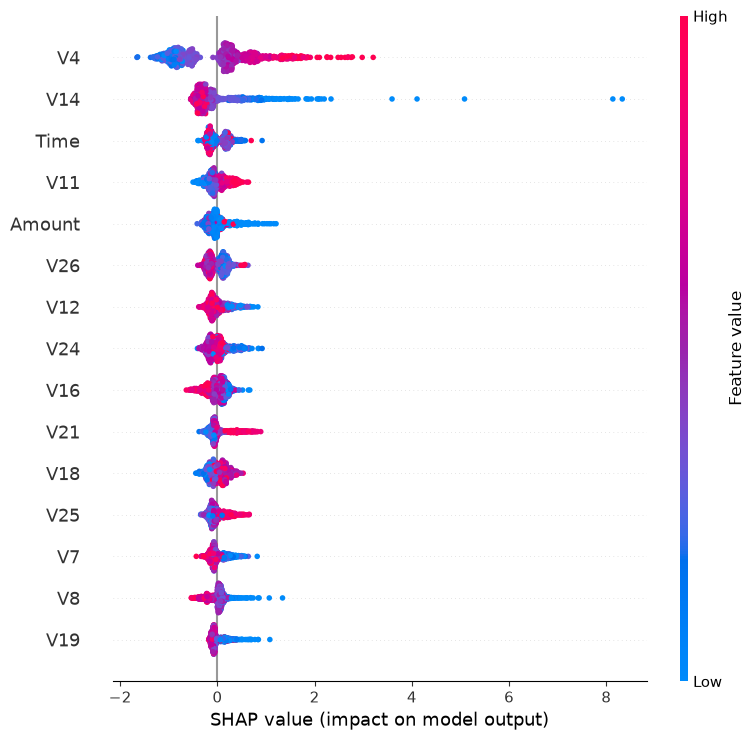

In [49]:
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_shap,
    max_display=15,
    show=False
)

plt.tight_layout()
plt.show()

In [50]:
fraud_indices = np.where(y_test.values == 1)[0]

fraud_idx = fraud_indices[0]

X_fraud = X_test.iloc[[fraud_idx]]

fraud_probability = rf_prob[fraud_idx]

print("Fraud Probability:", fraud_probability)
print("Risk Score:", round(fraud_probability * 100, 2))

Fraud Probability: 0.9804501682959212
Risk Score: 98.05


In [51]:
fraud_shap = explainer.shap_values(X_fraud)

print(fraud_shap.shape)


(1, 31)


In [52]:
fraud_explanation = pd.DataFrame({
    "Feature": X_fraud.columns,
    "Feature_Value": X_fraud.iloc[0].values,
    "SHAP_Value": fraud_shap[0]
})

fraud_explanation["Absolute_SHAP"] = np.abs(
    fraud_explanation["SHAP_Value"]
)

fraud_explanation = fraud_explanation.sort_values(
    "Absolute_SHAP",
    ascending=False
)

fraud_explanation.head(10)

,Feature,Feature_Value,SHAP_Value,Absolute_SHAP
14,V14,-5.210141,6.760567,6.760567
10,V10,-3.232153,2.920522,2.920522
4,V4,1.411850,1.268600,1.268600
17,V17,-3.267116,0.926327,0.926327
12,V12,-3.096915,0.824373,0.824373
29,Amount,0.760000,0.543989,0.543989
3,V3,-5.004247,0.539598,0.539598
7,V7,-1.413170,0.509848,0.509848
11,V11,2.858466,0.418215,0.418215
24,V24,-0.081049,-0.244441,0.244441


In [54]:
print("Expected value:", explainer.expected_value)
print("SHAP shape:", fraud_shap.shape)

Expected value: [-11.35754778]
SHAP shape: (1, 31)


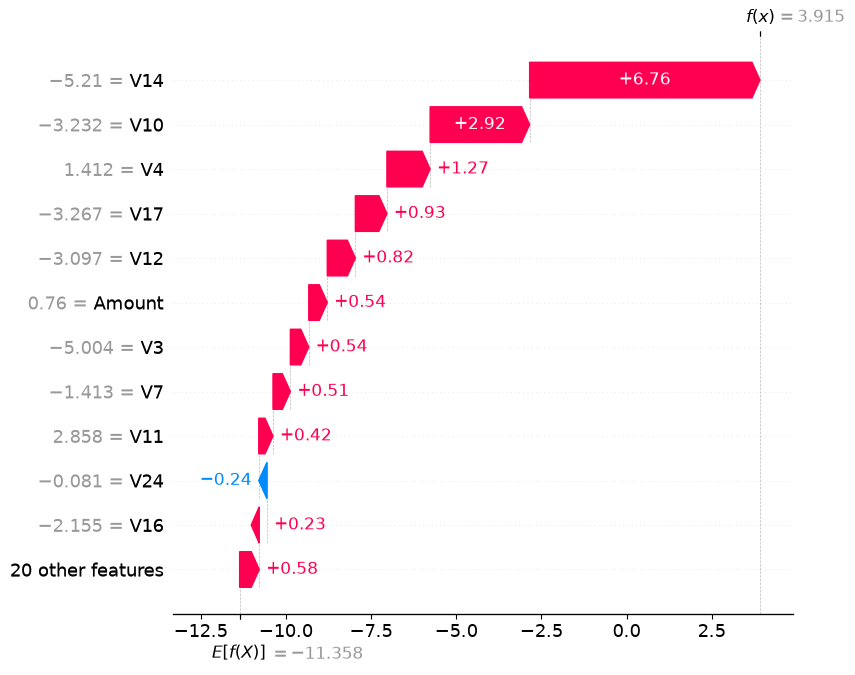

In [56]:
base_value = float(np.ravel(explainer.expected_value)[0])

shap.waterfall_plot(
    shap.Explanation(
        values=fraud_shap[0],
        base_values=base_value,
        data=X_fraud.iloc[0].values,
        feature_names=X_fraud.columns
    ),
    max_display=12
)

## Loading model and featurs
 

In [58]:
FINAL_THRESHOLD = 0.60

print("Final model: HistGradientBoosting")
print("Final threshold:", FINAL_THRESHOLD)

Final model: HistGradientBoosting
Final threshold: 0.6


In [59]:
import joblib
from pathlib import Path

ARTIFACT_DIR = Path("../artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

model_path = ARTIFACT_DIR / "fraud_model.joblib"

joblib.dump(tree_model, model_path)

print("Model saved to:", model_path)

Model saved to: ..\artifacts\fraud_model.joblib


In [60]:
import json

metadata = {
    "model_name": "HistGradientBoosting",
    "threshold": FINAL_THRESHOLD,
    "target_column": "Class",
    "feature_engineering": {
        "log_amount": "log1p(Amount)"
    }
}

metadata_path = ARTIFACT_DIR / "model_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata saved to:", metadata_path)

Metadata saved to: ..\artifacts\model_metadata.json


In [61]:
feature_names = X_train.columns.tolist()

metadata["feature_names"] = feature_names

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Number of features:", len(feature_names))
print(feature_names)

Number of features: 31
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'log_amount']


In [62]:
loaded_model = joblib.load(model_path)

print("Model loaded successfully.")
print(type(loaded_model))

Model loaded successfully.
<class 'sklearn.ensemble._hist_gradient_boosting.gradient_boosting.HistGradientBoostingClassifier'>


## Testing the loaded models and Features 



In [63]:
original_probability = tree_model.predict_proba(X_val.iloc[[0]])[:, 1][0]

loaded_probability = loaded_model.predict_proba(X_val.iloc[[0]])[:, 1][0]

print("Original probability:", original_probability)
print("Loaded probability:", loaded_probability)

Original probability: 2.77033861548424e-06
Loaded probability: 2.77033861548424e-06


In [64]:
sample = X_val.iloc[[0]].copy()

sample_processed = add_features(sample)

print(sample_processed.columns.tolist())

['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'log_amount']


## Perform one complete prediction test

In [65]:
sample = X_val.iloc[[0]].copy()

sample = add_features(sample)

probability = loaded_model.predict_proba(sample)[:, 1][0]

prediction = int(probability >= FINAL_THRESHOLD)

print("Fraud probability:", probability)
print("Prediction:", prediction)

Fraud probability: 2.77033861548424e-06
Prediction: 0


## Create risk-level logic

In [66]:
def get_risk_level(probability):
    if probability < 0.20:
        return "Low"
    elif probability < 0.60:
        return "Medium"
    elif probability < 0.80:
        return "High"
    else:
        return "Critical"

In [67]:
def get_decision(probability):
    if probability < 0.20:
        return "Approve"
    elif probability < 0.60:
        return "Monitor"
    elif probability < 0.80:
        return "Manual Review"
    else:
        return "Block Transaction"

test


In [68]:
probability = 0.87

print(get_risk_level(probability))
print(get_decision(probability))

Critical
Block Transaction


## Save these rules in metadata


In [69]:
metadata = {
    "model_name": "HistGradientBoosting",
    "threshold": 0.60,
    "target_column": "Class",

    "feature_engineering": {
        "log_amount": "log1p(Amount)"
    },

    "risk_levels": {
        "low": "< 0.20",
        "medium": "0.20 - < 0.60",
        "high": "0.60 - < 0.80",
        "critical": ">= 0.80"
    },

    "decisions": {
        "low": "Approve",
        "medium": "Monitor",
        "high": "Manual Review",
        "critical": "Block Transaction"
    },

    "feature_names": X_train.columns.tolist()
}

In [70]:
with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Metadata updated successfully.")

Metadata updated successfully.
